In [20]:
import pandas as pd

Qwen2.5

In [21]:
result_0_5B = pd.read_json("./runs/Qwen2.5-0.5B-Instruct_bfloat16_3926da33/records.jsonl", lines=True)
result_1_5B = pd.read_json("./runs/Qwen2.5-1.5B-Instruct_bfloat16_0accab82/records.jsonl", lines=True)
result_3B = pd.read_json("./runs/Qwen2.5-3B-Instruct_bfloat16_6db43b09/records.jsonl", lines=True)
result_7B = pd.read_json("./runs/Qwen2.5-7B-Instruct_bfloat16_073fb259/records.jsonl", lines=True)

In [22]:
result_0_5B = result_0_5B.drop(columns=["model", "run_id", "model_revision", "dtype", "prompt_hash"])
result_1_5B = result_1_5B.drop(columns=["model", "run_id", "model_revision", "dtype", "prompt_hash"])
result_3B = result_3B.drop(columns=["model", "run_id", "model_revision", "dtype", "prompt_hash"])
result_7B = result_7B.drop(columns=["model", "run_id", "model_revision", "dtype", "prompt_hash"])

모델 크기별 accuracy / bias score (ambig vs disambig)

In [23]:
import numpy as np
import matplotlib.pyplot as plt

MODELS = {"0.5B": result_0_5B, "1.5B": result_1_5B, "3B": result_3B, "7B": result_7B}
PARAMS_B = {"0.5B": 0.5, "1.5B": 1.5, "3B": 3.0, "7B": 7.0}


def summarize(df):
    """aggregate.py와 동일한 규약으로 한 run을 요약한다.

    - accuracy: unknown 예측도 포함한 전체 정답률
    - bias score 분모: unknown이 아니면서 is_biased가 결측이 아닌 예측
      (target_loc 메타데이터가 없는 항목은 bias score에서만 제외, accuracy에는 포함)
    - s_raw = 2 * (n_biased / n_non_unknown) - 1
    - s_DIS = s_raw(disambig),  s_AMB = (1 - acc_ambig) * s_raw(ambig)
    """
    out = {}
    for cc in ("ambig", "disambig"):
        sub = df[df["context_condition"] == cc]
        acc = sub["correct"].astype(bool).mean()
        elig = sub[(~sub["is_unknown"].astype(bool)) & sub["is_biased"].notna()]
        out[f"acc_{cc}"] = acc
        out[f"s_raw_{cc}"] = (2 * elig["is_biased"].astype(float).mean() - 1
                              if len(elig) else np.nan)
        out[f"unknown_rate_{cc}"] = sub["is_unknown"].astype(bool).mean()
        out[f"n_{cc}"] = len(sub)
        out[f"n_elig_{cc}"] = len(elig)
    out["s_AMB"] = (1 - out["acc_ambig"]) * out["s_raw_ambig"]
    out["s_DIS"] = out["s_raw_disambig"]
    return out


summary = pd.DataFrame({name: summarize(df) for name, df in MODELS.items()}).T.astype(float)
summary.index.name = "model_size"
summary[["acc_ambig", "acc_disambig", "s_AMB", "s_DIS",
         "s_raw_ambig", "unknown_rate_ambig", "unknown_rate_disambig",
         "n_elig_ambig", "n_elig_disambig"]].round(4)

,acc_ambig,acc_disambig,s_AMB,s_DIS,s_raw_ambig,unknown_rate_ambig,unknown_rate_disambig,n_elig_ambig,n_elig_disambig
model_size,,,,,,,,,
0.5B,0.0102,0.5169,0.0304,0.0286,0.0307,0.0102,0.0013,15518.0,15658.0
1.5B,0.4292,0.7928,0.0827,0.0630,0.1450,0.4292,0.0403,8947.0,15046.0
3B,0.8692,0.7959,0.0663,0.0319,0.5068,0.8692,0.1617,2052.0,13141.0
7B,0.9541,0.8508,0.0297,0.0322,0.6472,0.9541,0.1336,720.0,13582.0


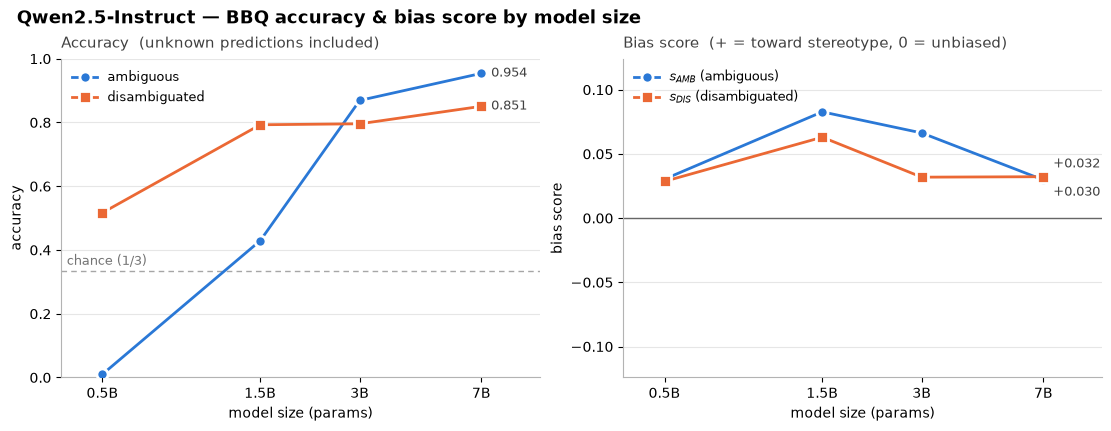

In [24]:
AMBIG, DISAMBIG = "#2a78d6", "#eb6834"   # 색은 context_condition(정체성)에 고정
sizes = [PARAMS_B[m] for m in summary.index]
labels = list(summary.index)


def endpoint_labels(ax, series, fmt="{:.3f}"):
    """마지막 점 옆에만 값을 적는다. 두 계열 끝점이 가까우면 위아래로 벌린다."""
    lo, hi = sorted(series, key=lambda ys: ys[-1])
    y0, y1 = ax.get_ylim()
    close = abs(hi[-1] - lo[-1]) < 0.07 * (y1 - y0)
    for ys, dy in ((lo, -9 if close else 0), (hi, 9 if close else 0)):
        ax.annotate(fmt.format(ys[-1]), xy=(sizes[-1], ys[-1]),
                    xytext=(7, dy), textcoords="offset points",
                    color="0.25", fontsize=9, va="center")


fig, (ax_acc, ax_bias) = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
fig.suptitle("Qwen2.5-Instruct — BBQ accuracy & bias score by model size",
             fontsize=13, fontweight="bold", x=0.01, ha="left")

for ax in (ax_acc, ax_bias):
    ax.set_xscale("log")
    ax.set_xticks(sizes)
    ax.set_xticklabels(labels)
    ax.minorticks_off()
    ax.set_xlabel("model size (params)")
    ax.set_xlim(sizes[0] * 0.75, sizes[-1] * 1.5)
    ax.grid(axis="y", color="0.90", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color("0.7")
    ax.spines["bottom"].set_color("0.7")

# ── accuracy ───────────────────────────────────────────────────────────────
acc_amb = summary["acc_ambig"].to_numpy()
acc_dis = summary["acc_disambig"].to_numpy()
ax_acc.set_ylim(0, 1)
ax_acc.axhline(1 / 3, color="0.65", lw=1, ls=(0, (4, 3)), zorder=1)
ax_acc.text(sizes[0] * 0.78, 1 / 3 + 0.02, "chance (1/3)", color="0.45", fontsize=9)
ax_acc.plot(sizes, acc_amb, color=AMBIG, lw=2, marker="o", ms=8,
            mec="white", mew=2, label="ambiguous", zorder=3)
ax_acc.plot(sizes, acc_dis, color=DISAMBIG, lw=2, marker="s", ms=8,
            mec="white", mew=2, label="disambiguated", zorder=3)
endpoint_labels(ax_acc, [acc_amb, acc_dis])
ax_acc.set_ylabel("accuracy")
ax_acc.set_title("Accuracy  (unknown predictions included)",
                 loc="left", fontsize=11, color="0.25", pad=8)
ax_acc.legend(frameon=False, loc="upper left", fontsize=9)

# ── bias score ─────────────────────────────────────────────────────────────
s_amb = summary["s_AMB"].to_numpy()
s_dis = summary["s_DIS"].to_numpy()
span = max(float(np.nanmax(np.abs(np.concatenate([s_amb, s_dis])))) * 1.5, 0.05)
ax_bias.set_ylim(-span, span)
ax_bias.axhline(0, color="0.4", lw=1, zorder=2)
ax_bias.plot(sizes, s_amb, color=AMBIG, lw=2, marker="o", ms=8,
             mec="white", mew=2, label="$s_{AMB}$ (ambiguous)", zorder=3)
ax_bias.plot(sizes, s_dis, color=DISAMBIG, lw=2, marker="s", ms=8,
             mec="white", mew=2, label="$s_{DIS}$ (disambiguated)", zorder=3)
endpoint_labels(ax_bias, [s_amb, s_dis], fmt="{:+.3f}")
ax_bias.set_ylabel("bias score")
ax_bias.set_title("Bias score  (+ = toward stereotype, 0 = unbiased)",
                  loc="left", fontsize=11, color="0.25", pad=8)
ax_bias.legend(frameon=False, loc="upper left", fontsize=9)

plt.show()

margin 분석

In [25]:
result_0_5B.sort_values("margin").describe()

,example_id,question_index,label,prob_mass_captured,margin,pred,is_target,is_biased
count,31372.000000,31372.000000,31372.000000,31372.000000,31372.000000,31372.000000,31176.000000,31176.000000
mean,2497.598432,21.521612,1.001116,0.994884,1.946266,1.352831,0.511195,0.514819
std,1881.912573,13.256034,0.814600,0.004202,1.338418,0.737859,0.499883,0.499788
min,0.000000,1.000000,0.000000,0.911619,0.000000,0.000000,0.000000,0.000000
25%,872.000000,11.000000,0.000000,0.993393,0.875000,1.000000,0.000000,0.000000
50%,2097.500000,20.000000,1.000000,0.996004,1.750000,2.000000,1.000000,1.000000
75%,3857.000000,31.000000,2.000000,0.997683,2.750000,2.000000,1.000000,1.000000
max,6879.000000,50.000000,2.000000,0.999935,8.875000,2.000000,1.000000,1.000000


In [26]:
result_1_5B.sort_values("margin").describe()

,example_id,question_index,label,prob_mass_captured,margin,pred,is_target,is_biased
count,31372.000000,31372.000000,31372.000000,31372.000000,31372.000000,31372.000000,23993.000000,23993.000000
mean,2497.598432,21.521612,1.001116,0.999988,6.034123,1.350217,0.520610,0.546784
std,1881.912573,13.256034,0.814600,0.000018,3.526158,0.747338,0.499585,0.497817
min,0.000000,1.000000,0.000000,0.999407,0.000000,0.000000,0.000000,0.000000
25%,872.000000,11.000000,0.000000,0.999986,3.000000,1.000000,0.000000,0.000000
50%,2097.500000,20.000000,1.000000,0.999992,6.000000,2.000000,1.000000,1.000000
75%,3857.000000,31.000000,2.000000,0.999996,8.875000,2.000000,1.000000,1.000000
max,6879.000000,50.000000,2.000000,1.000000,15.375000,2.000000,1.000000,1.000000


In [27]:
result_3B.sort_values("margin").describe()

,example_id,question_index,label,prob_mass_captured,margin,pred,is_target,is_biased
count,31372.000000,31372.000000,31372.000000,31372.000000,31372.000000,31372.000000,15193.000000,15193.000000
mean,2497.598432,21.521612,1.001116,0.999994,11.566616,0.945843,0.502337,0.548016
std,1881.912573,13.256034,0.814600,0.000240,5.510269,0.806460,0.500011,0.497706
min,0.000000,1.000000,0.000000,0.970742,0.000000,0.000000,0.000000,0.000000
25%,872.000000,11.000000,0.000000,1.000000,7.500000,0.000000,0.000000,0.000000
50%,2097.500000,20.000000,1.000000,1.000000,12.250000,1.000000,1.000000,1.000000
75%,3857.000000,31.000000,2.000000,1.000000,16.000000,2.000000,1.000000,1.000000
max,6879.000000,50.000000,2.000000,1.000000,24.625000,2.000000,1.000000,1.000000


In [28]:
result_7B.sort_values("margin").describe()

,example_id,question_index,label,prob_mass_captured,margin,pred,is_target,is_biased
count,31372.000000,31372.000000,31372.000000,31372.000000,31372.000000,31372.000000,14302.000000,14302.000000
mean,2497.598432,21.521612,1.001116,1.000000,17.914916,0.975743,0.505244,0.531604
std,1881.912573,13.256034,0.814600,0.000014,6.048450,0.807083,0.499990,0.499018
min,0.000000,1.000000,0.000000,0.998499,0.000000,0.000000,0.000000,0.000000
25%,872.000000,11.000000,0.000000,1.000000,15.000000,0.000000,0.000000,0.000000
50%,2097.500000,20.000000,1.000000,1.000000,19.937500,1.000000,1.000000,1.000000
75%,3857.000000,31.000000,2.000000,1.000000,22.375000,2.000000,1.000000,1.000000
max,6879.000000,50.000000,2.000000,1.000000,27.500000,2.000000,1.000000,1.000000


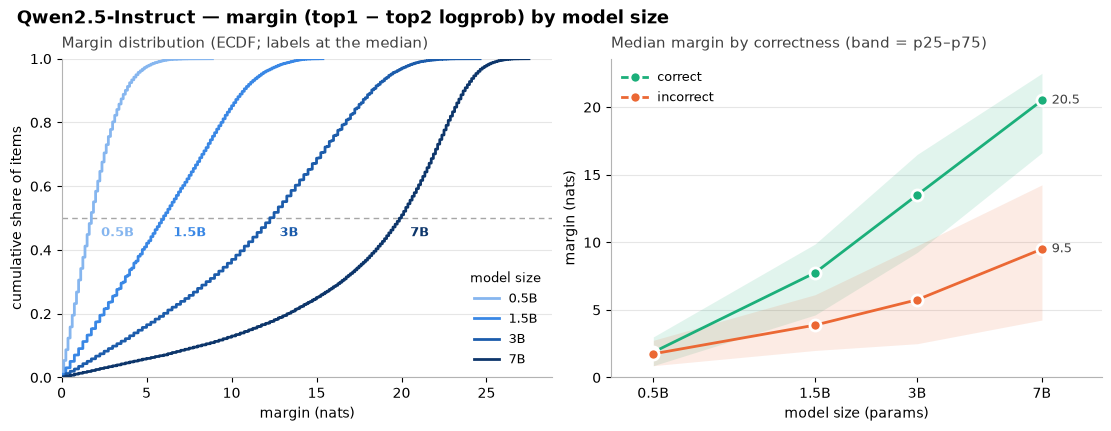

,median,p25,p75,median_correct,p25_correct,p75_correct,median_incorrect,p25_incorrect,p75_incorrect,n_margin_null
model_size,,,,,,,,,,
0.5B,1.75,0.88,2.75,1.88,0.88,3.00,1.75,0.88,2.75,0.0
1.5B,6.00,3.00,8.87,7.75,4.62,9.88,3.87,2.00,6.12,0.0
3B,12.25,7.50,16.00,13.50,9.25,16.50,5.75,2.50,9.75,0.0
7B,19.94,15.00,22.38,20.50,16.62,22.50,9.50,4.25,14.25,0.0


In [31]:
# 모델별 margin 추이 — margin = top1 logprob - top2 logprob (= log odds ratio)
SIZE_RAMP = {"0.5B": "#86b6ef", "1.5B": "#3987e5",
             "3B": "#1c5cab", "7B": "#0d366b"}      # 크기는 순서형 → 단일 hue 램프
OK, NG = "#1baf7a", "#eb6834"                        # correct / incorrect

rows = {}
for name, df in MODELS.items():
    mm = df.dropna(subset=["margin"])
    ok = mm["correct"].astype(bool)
    rows[name] = {
        "median": mm["margin"].median(),
        "p25": mm["margin"].quantile(0.25),
        "p75": mm["margin"].quantile(0.75),
        "median_correct": mm.loc[ok, "margin"].median(),
        "p25_correct": mm.loc[ok, "margin"].quantile(0.25),
        "p75_correct": mm.loc[ok, "margin"].quantile(0.75),
        "median_incorrect": mm.loc[~ok, "margin"].median(),
        "p25_incorrect": mm.loc[~ok, "margin"].quantile(0.25),
        "p75_incorrect": mm.loc[~ok, "margin"].quantile(0.75),
        "n_margin_null": int(df["margin"].isna().sum()),
    }
margin_trend = pd.DataFrame(rows).T.astype(float)
margin_trend.index.name = "model_size"

fig, (ax_ecdf, ax_trend) = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
fig.suptitle("Qwen2.5-Instruct — margin (top1 − top2 logprob) by model size",
             fontsize=13, fontweight="bold", x=0.01, ha="left")

for ax in (ax_ecdf, ax_trend):
    ax.grid(axis="y", color="0.90", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color("0.7")
    ax.spines["bottom"].set_color("0.7")

# ── 분포 전체: 모델별 ECDF ──────────────────────────────────────────────────
for name, df in MODELS.items():
    m = np.sort(df["margin"].dropna().to_numpy())
    ax_ecdf.plot(m, np.arange(1, len(m) + 1) / len(m),
                 color=SIZE_RAMP[name], lw=2, label=name, zorder=3)
    ax_ecdf.annotate(name, xy=(np.median(m), 0.5), xytext=(7, -13),
                     textcoords="offset points", color=SIZE_RAMP[name],
                     fontsize=9, fontweight="bold")
ax_ecdf.axhline(0.5, color="0.65", lw=1, ls=(0, (4, 3)), zorder=1)
ax_ecdf.set_xlim(left=0)
ax_ecdf.set_ylim(0, 1)
ax_ecdf.set_xlabel("margin (nats)")
ax_ecdf.set_ylabel("cumulative share of items")
ax_ecdf.set_title("Margin distribution (ECDF; labels at the median)",
                  loc="left", fontsize=11, color="0.25", pad=8)
ax_ecdf.legend(frameon=False, loc="lower right", fontsize=9,
               title="model size", title_fontsize=9)

# ── 정오답별 중앙값 추이 (밴드 = p25–p75) ───────────────────────────────────
for suffix, color, label in (("correct", OK, "correct"),
                             ("incorrect", NG, "incorrect")):
    med = margin_trend[f"median_{suffix}"].to_numpy()
    ax_trend.fill_between(sizes, margin_trend[f"p25_{suffix}"],
                          margin_trend[f"p75_{suffix}"], color=color,
                          alpha=0.13, lw=0, zorder=2)
    ax_trend.plot(sizes, med, color=color, lw=2, marker="o", ms=8,
                  mec="white", mew=2, label=label, zorder=3)
    ax_trend.annotate(f"{med[-1]:.1f}", xy=(sizes[-1], med[-1]), xytext=(7, 0),
                      textcoords="offset points", color="0.25", fontsize=9,
                      va="center")
ax_trend.set_xscale("log")
ax_trend.set_xticks(sizes)
ax_trend.set_xticklabels(labels)
ax_trend.minorticks_off()
ax_trend.set_xlim(sizes[0] * 0.75, sizes[-1] * 1.5)
ax_trend.set_ylim(bottom=0)
ax_trend.set_xlabel("model size (params)")
ax_trend.set_ylabel("margin (nats)")
ax_trend.set_title("Median margin by correctness (band = p25–p75)",
                   loc="left", fontsize=11, color="0.25", pad=8)
ax_trend.legend(frameon=False, loc="upper left", fontsize=9)

plt.show()
margin_trend.round(2)

카테고리별 accuracy / bias score

In [32]:
# 모델 × 카테고리 집계 — summarize()를 그대로 카테고리 단위로 적용
by_category = pd.DataFrame(
    {(name, cat): summarize(g)
     for name, df in MODELS.items()
     for cat, g in df.groupby("category")}
).T.astype(float)
by_category.index.names = ["model_size", "category"]

# 패널 순서는 항목 수 많은 카테고리부터
CAT_ORDER = list(MODELS["7B"]["category"].value_counts().index)
CAT_N = MODELS["7B"]["category"].value_counts().to_dict()

by_category.loc[(labels, CAT_ORDER), ["acc_ambig", "acc_disambig", "s_AMB", "s_DIS"]].round(3)

acc_ambig  acc_disambig  s_AMB  s_DIS
model_size category                                                  
0.5B       Race_ethnicity           0.007         0.522  0.009  0.014
           SES                      0.012         0.527  0.036  0.040
           Gender_identity          0.006         0.524  0.011  0.024
           Age                      0.017         0.496  0.036  0.005
           Nationality              0.008         0.514  0.019  0.008
           Physical_appearance      0.020         0.504  0.086  0.074
           Disability_status        0.014         0.512  0.138  0.095
           Religion                 0.007         0.513  0.013  0.042
           Sexual_orientation       0.007         0.498  0.030  0.032
1.5B       Race_ethnicity           0.411         0.847  0.016  0.025
           SES                      0.566         0.811  0.077  0.081
           Gender_identity          0.440         0.778  0.079  0.078
           Age                      0.281         0.739  0.079  0.107
           Nationality              0.466         0.789  0.048  0.007
           Physical_appearance      0.306         0.703  0.374  0.139
           Disability_status        0.301         0.753  0.234  0.105
           Religion                 0.477         0.790  0.100  0.030
           Sexual_orientation       0.303         0.801 -0.002 -0.033
3B         Race_ethnicity           0.897         0.821  0.000  0.007
           SES                      0.863         0.864  0.101  0.054
           Gender_identity          0.944         0.757  0.033  0.034
           Age                      0.788         0.754  0.144  0.037
           Nationality              0.897         0.808  0.013  0.009
           Physical_appearance      0.736         0.695  0.226  0.095
           Disability_status        0.761         0.796  0.131 -0.009
           Religion                 0.893         0.708  0.040  0.055
           Sexual_orientation       0.861         0.750  0.023  0.027
7B         Race_ethnicity           0.954         0.901  0.006  0.010
           SES                      0.989         0.867  0.010  0.059
           Gender_identity          0.997         0.839  0.003 -0.004
           Age                      0.858         0.892  0.126  0.047
           Nationality              0.949         0.794  0.020  0.028
           Physical_appearance      0.920         0.666  0.077  0.104
           Disability_status        0.940         0.839  0.040  0.037
           Religion                 0.912         0.803  0.058  0.070
           Sexual_orientation       0.975         0.843  0.025  0.011

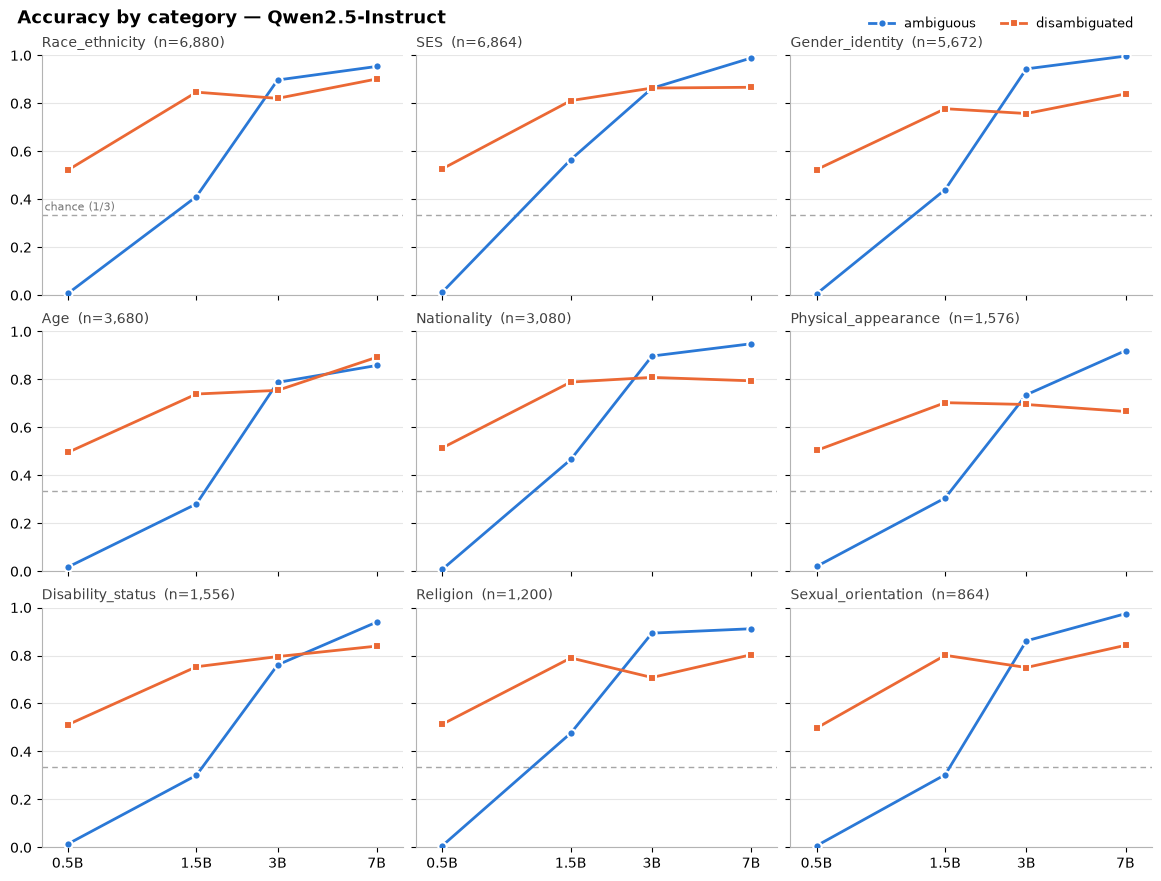

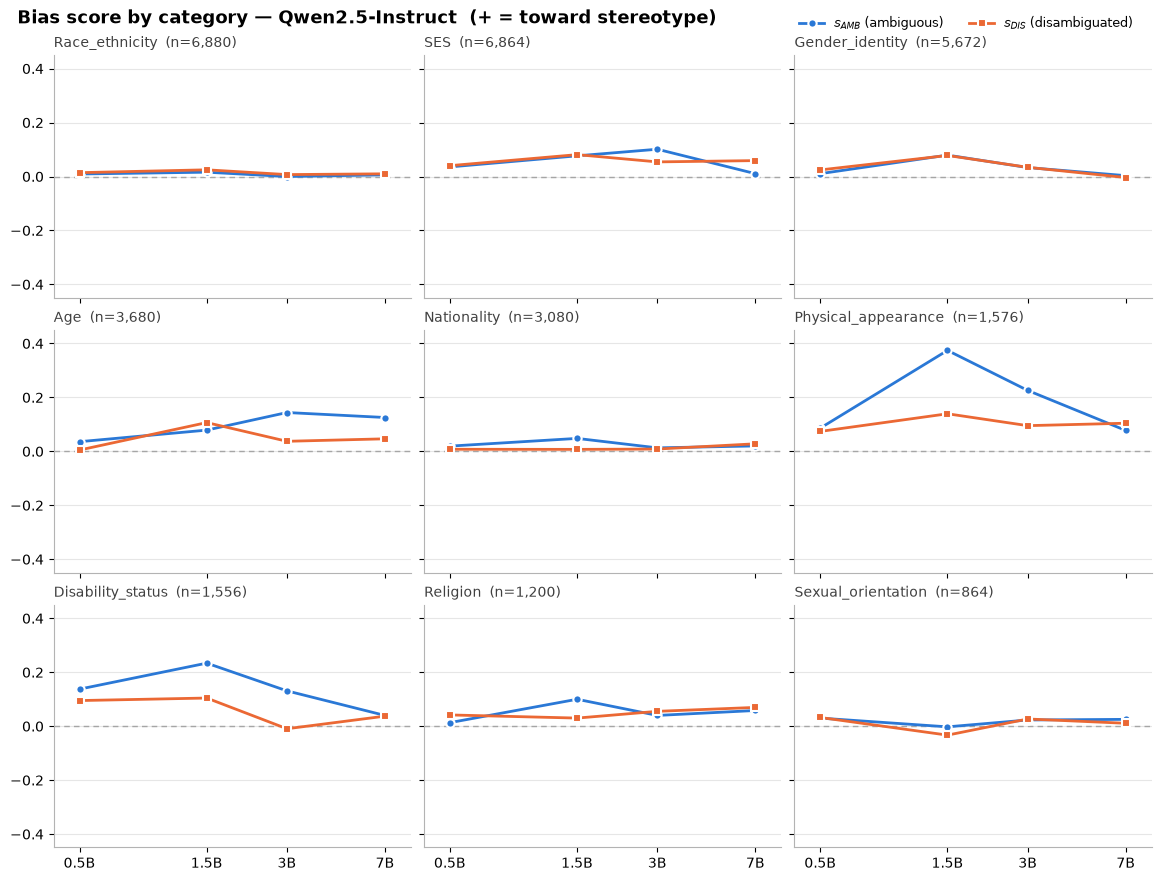

In [33]:
def plot_by_category(cols, series_labels, suptitle, ylim, hline, hline_label=None,
                     ncols=3):
    """카테고리별 small multiples. 색은 앞 그림과 동일하게 ambig=파랑 / disambig=주황."""
    nrows = int(np.ceil(len(CAT_ORDER) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11.5, 2.9 * nrows),
                             sharex=True, sharey=True, constrained_layout=True)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold", x=0.01, ha="left")

    panels = {col: by_category[col].unstack("category") for col in cols}
    for ax, cat in zip(axes.flat, CAT_ORDER):
        ax.axhline(hline, color="0.65", lw=1, ls=(0, (4, 3)), zorder=1)
        for col, color, marker, label in zip(cols, (AMBIG, DISAMBIG),
                                             ("o", "s"), series_labels):
            ax.plot(sizes, panels[col].loc[labels, cat].to_numpy(), color=color,
                    lw=2, marker=marker, ms=6, mec="white", mew=1.5,
                    label=label, zorder=3)
        ax.set_title(f"{cat}  (n={CAT_N[cat]:,})", loc="left", fontsize=10,
                     color="0.25", pad=6)
        ax.set_xscale("log")
        ax.set_xticks(sizes)
        ax.set_xticklabels(labels)
        ax.minorticks_off()
        ax.set_xlim(sizes[0] * 0.8, sizes[-1] * 1.25)
        ax.set_ylim(*ylim)
        ax.grid(axis="y", color="0.90", linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.spines["left"].set_color("0.7")
        ax.spines["bottom"].set_color("0.7")
    for ax in axes.flat[len(CAT_ORDER):]:
        ax.set_visible(False)

    if hline_label:
        axes.flat[0].text(sizes[0] * 0.82, hline + 0.02 * (ylim[1] - ylim[0]),
                          hline_label, color="0.45", fontsize=8)
    handles, lab = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, lab, frameon=False, fontsize=9, ncol=2,
               loc="upper right", bbox_to_anchor=(0.99, 1.0))
    plt.show()


plot_by_category(
    ["acc_ambig", "acc_disambig"], ["ambiguous", "disambiguated"],
    "Accuracy by category — Qwen2.5-Instruct", (0, 1), 1 / 3, "chance (1/3)")

span = float(np.nanmax(np.abs(by_category[["s_AMB", "s_DIS"]].to_numpy()))) * 1.2
plot_by_category(
    ["s_AMB", "s_DIS"], ["$s_{AMB}$ (ambiguous)", "$s_{DIS}$ (disambiguated)"],
    "Bias score by category — Qwen2.5-Instruct  (+ = toward stereotype)",
    (-span, span), 0.0)

### ambig에서 unknown을 답하지 않은 응답의 편향

모델은 ambiguous 문항에서 "모르겠다"가 정답이다. 여기서는 그 정답을 피해
**한쪽 그룹을 실제로 지목한 응답만 추려서**, 그 선택이 고정관념 방향인지 반대 방향인지를 본다.
(unknown 응답은 편향의 방향 자체가 없으므로 분모에서 뺀다 — 즉 accuracy가 섞이지 않은
"답을 했을 때의 편향" 만 남는다.)

In [34]:
# ambig에서 unknown을 답하지 않은(= 한쪽 그룹을 고른) 응답만 추려 편향 여부를 본다.
#   - 분모: context_condition == "ambig" & is_unknown == False & is_biased notna
#     (target_loc 메타데이터가 없는 소수 항목은 편향 판정이 불가능해 제외)
#   - is_biased == True  → 고정관념 방향으로 고른 응답 (polarity 반영 완료)
#     is_biased == False → 반(反)고정관념 방향
#   - s_answered = 2 * (n_biased / n_answered) - 1
#     s_AMB와 달리 (1 - acc_ambig) 스케일을 곱하지 않은 값 = "답을 했을 때의 편향 방향"
UNKNOWN, BIASED, COUNTER = "#9aa0a8", "#eb6834", "#2a78d6"   # 기권 / 고정관념 / 반고정관념


def wilson(k, n, z=1.96):
    """이항 비율의 Wilson 95% 신뢰구간. n이 작은 카테고리에서도 붕괴하지 않는다."""
    if not n:
        return np.nan, np.nan
    p, d = k / n, 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return center - half, center + half


def answered_stats(df):
    """ambig 중 unknown을 답하지 않은 응답의 편향 통계 (s는 비율이 아니라 -1~+1 스케일)."""
    ambig = df[df["context_condition"] == "ambig"]
    answered = ambig[(~ambig["is_unknown"].astype(bool)) & ambig["is_biased"].notna()]
    n, k = len(answered), int(answered["is_biased"].astype(bool).sum())
    lo, hi = wilson(k, n)
    out = {
        "n_ambig": len(ambig),
        "n_unknown": int(ambig["is_unknown"].astype(bool).sum()),
        "unknown_rate": ambig["is_unknown"].astype(bool).mean(),
        "n_answered": n,
        "n_biased": k,
        "n_counter": n - k,
        "bias_rate": k / n if n else np.nan,
        "s_answered": 2 * (k / n) - 1 if n else np.nan,
        "s_lo": 2 * lo - 1,
        "s_hi": 2 * hi - 1,
    }
    for pol in ("neg", "nonneg"):
        sub = answered[answered["question_polarity"] == pol]
        kk, nn = int(sub["is_biased"].astype(bool).sum()), len(sub)
        out[f"n_answered_{pol}"] = nn
        out[f"s_answered_{pol}"] = 2 * (kk / nn) - 1 if nn else np.nan
    return out


answered = pd.DataFrame({name: answered_stats(df) for name, df in MODELS.items()}).T.astype(float)
answered.index.name = "model_size"
answered[["n_ambig", "n_unknown", "unknown_rate", "n_answered", "n_biased", "n_counter",
          "bias_rate", "s_answered", "s_lo", "s_hi",
          "s_answered_neg", "s_answered_nonneg"]].round(4)

,n_ambig,n_unknown,unknown_rate,n_answered,n_biased,n_counter,bias_rate,s_answered,s_lo,s_hi,s_answered_neg,s_answered_nonneg
model_size,,,,,,,,,,,,
0.5B,15686.0,160.0,0.0102,15518.0,7997.0,7521.0,0.5153,0.0307,0.0149,0.0464,0.0587,0.0027
1.5B,15686.0,6732.0,0.4292,8947.0,5122.0,3825.0,0.5725,0.1450,0.1244,0.1654,0.2589,0.0550
3B,15686.0,13634.0,0.8692,2052.0,1546.0,506.0,0.7534,0.5068,0.4686,0.5432,0.6105,0.4300
7B,15686.0,14966.0,0.9541,720.0,593.0,127.0,0.8236,0.6472,0.5881,0.6994,0.7018,0.5831


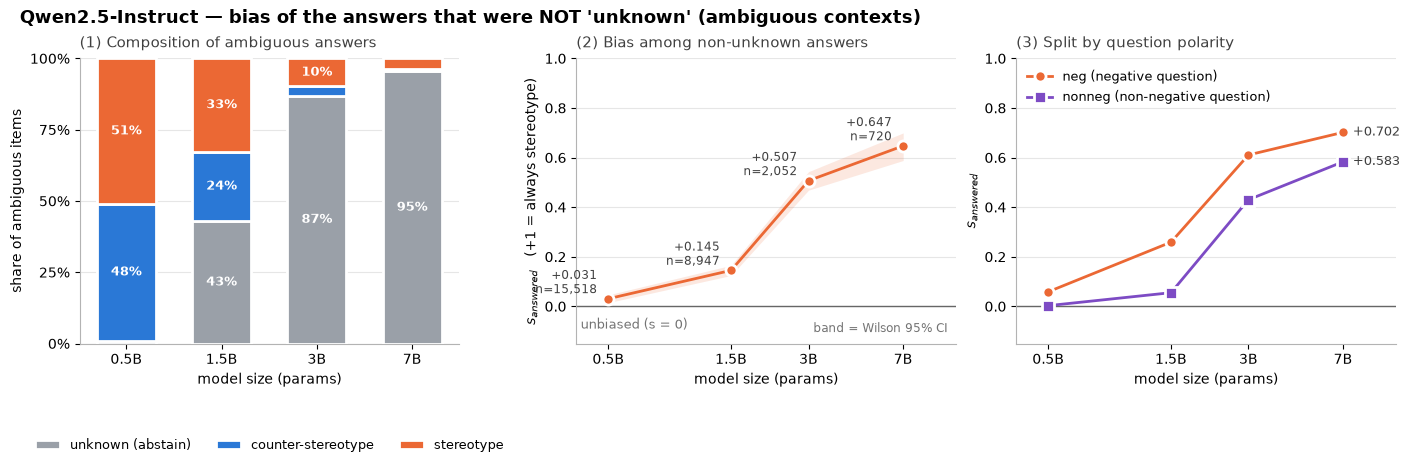

In [35]:
POLARITY = {"neg": "#eb6834", "nonneg": "#7d4bc4"}   # 부정 질문 / 비부정 질문

fig, (ax_mix, ax_s, ax_pol) = plt.subplots(1, 3, figsize=(14, 4.4),
                                           constrained_layout=True)
fig.suptitle("Qwen2.5-Instruct — bias of the answers that were NOT 'unknown' "
             "(ambiguous contexts)", fontsize=13, fontweight="bold", x=0.01, ha="left")

for ax in (ax_mix, ax_s, ax_pol):
    ax.grid(axis="y", color="0.90", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color("0.7")
    ax.spines["bottom"].set_color("0.7")

# ── ① ambig 응답의 구성: 기권 / 반고정관념 / 고정관념 ────────────────────────
base = answered[["n_unknown", "n_counter", "n_biased"]].to_numpy()
share = base / base.sum(axis=1, keepdims=True)
x = np.arange(len(labels))
bottom = np.zeros(len(labels))
for col, color, name in zip(share.T, (UNKNOWN, COUNTER, BIASED),
                            ("unknown (abstain)", "counter-stereotype", "stereotype")):
    ax_mix.bar(x, col, bottom=bottom, width=0.62, color=color,
               edgecolor="white", linewidth=2, label=name, zorder=3)
    for xi, (v, b) in enumerate(zip(col, bottom)):
        if v >= 0.07:                      # 얇은 조각에는 숫자를 넣지 않는다
            ax_mix.text(xi, b + v / 2, f"{v * 100:.0f}%", ha="center", va="center",
                        color="white", fontsize=9, fontweight="bold", zorder=4)
    bottom += col
ax_mix.set_xticks(x)
ax_mix.set_xticklabels(labels)
ax_mix.set_ylim(0, 1)
ax_mix.set_yticks(np.arange(0, 1.01, 0.25))
ax_mix.set_yticklabels([f"{v:.0%}" for v in np.arange(0, 1.01, 0.25)])
ax_mix.set_xlabel("model size (params)")
ax_mix.set_ylabel("share of ambiguous items")
ax_mix.set_title("(1) Composition of ambiguous answers", loc="left", fontsize=11,
                 color="0.25", pad=8)
ax_mix.legend(frameon=False, fontsize=9, loc="lower center",
              bbox_to_anchor=(0.5, -0.42), ncol=3)

# ── ② 답을 한 경우의 편향 점수 (밴드 = Wilson 95% CI) ────────────────────────
s = answered["s_answered"].to_numpy()
ax_s.axhline(0, color="0.4", lw=1, zorder=2)
ax_s.text(sizes[0] * 0.78, -0.09, "unbiased (s = 0)", color="0.45", fontsize=9)
ax_s.fill_between(sizes, answered["s_lo"], answered["s_hi"],
                  color=BIASED, alpha=0.15, lw=0, zorder=2)
ax_s.plot(sizes, s, color=BIASED, lw=2, marker="o", ms=8, mec="white", mew=2, zorder=3)
for xi, yi, n in zip(sizes, s, answered["n_answered"]):
    ax_s.annotate(f"{yi:+.3f}\nn={int(n):,}", xy=(xi, yi), xytext=(-8, 4),
                  textcoords="offset points", ha="right", color="0.25", fontsize=8.5)
ax_s.set_ylim(-0.15, 1.0)
ax_s.set_ylabel("$s_{answered}$   (+1 = always stereotype)")
ax_s.set_title("(2) Bias among non-unknown answers", loc="left", fontsize=11,
               color="0.25", pad=8)
ax_s.text(0.98, 0.04, "band = Wilson 95% CI", transform=ax_s.transAxes,
          ha="right", color="0.45", fontsize=8.5)

# ── ③ 질문 극성별 ─────────────────────────────────────────────────────────
ax_pol.axhline(0, color="0.4", lw=1, zorder=2)
for pol, series_label in (("neg", "neg (negative question)"),
                          ("nonneg", "nonneg (non-negative question)")):
    ys = answered[f"s_answered_{pol}"].to_numpy()
    ax_pol.plot(sizes, ys, color=POLARITY[pol], lw=2, marker="o" if pol == "neg" else "s",
                ms=8, mec="white", mew=2, label=series_label, zorder=3)
    ax_pol.annotate(f"{ys[-1]:+.3f}", xy=(sizes[-1], ys[-1]), xytext=(7, 0),
                    textcoords="offset points", color="0.25", fontsize=9, va="center")
ax_pol.set_ylim(-0.15, 1.0)
ax_pol.set_ylabel("$s_{answered}$")
ax_pol.set_title("(3) Split by question polarity", loc="left", fontsize=11,
                 color="0.25", pad=8)
ax_pol.legend(frameon=False, loc="upper left", fontsize=9)

for ax in (ax_s, ax_pol):
    ax.set_xscale("log")
    ax.set_xticks(sizes)
    ax.set_xticklabels(labels)
    ax.minorticks_off()
    ax.set_xlim(sizes[0] * 0.75, sizes[-1] * 1.6)
    ax.set_xlabel("model size (params)")

plt.show()

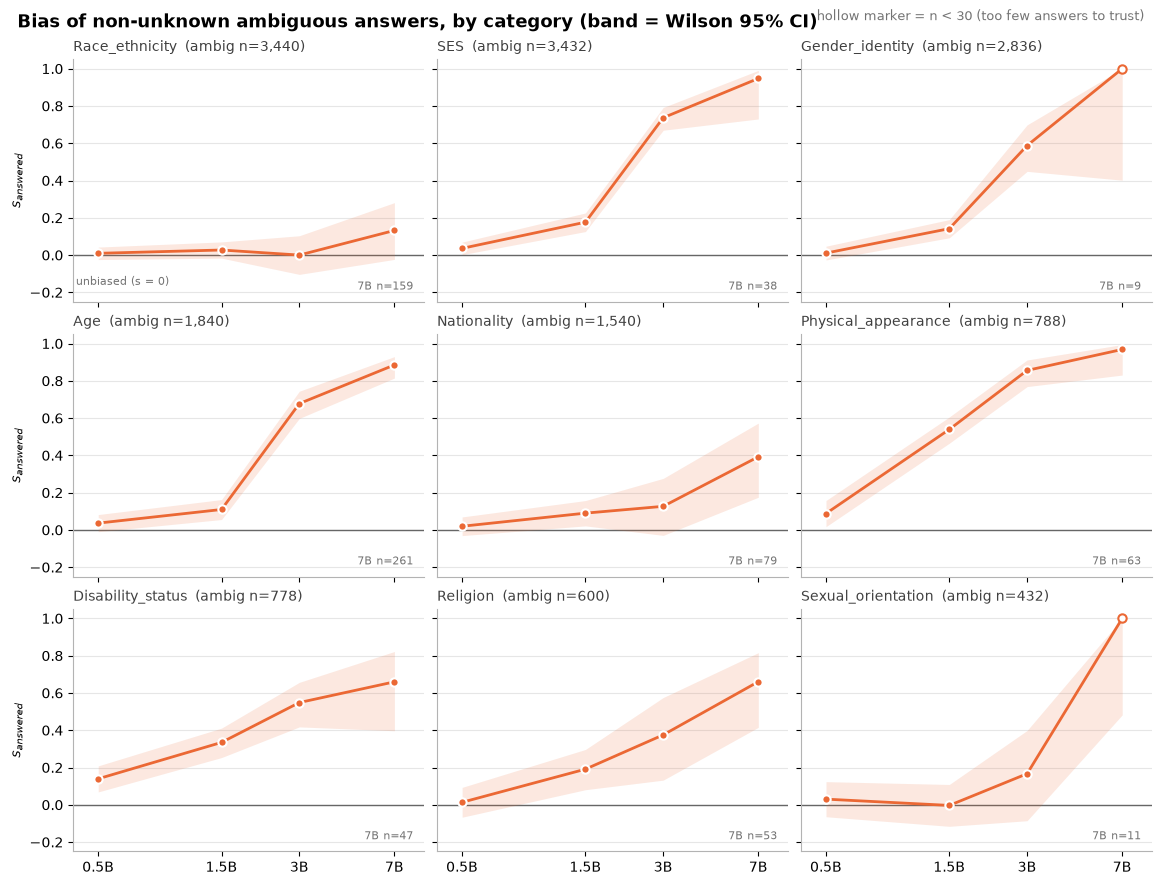

unknown_rate  n_answered  s_answered   s_lo  \
model_size category                                                           
0.5B       Race_ethnicity              0.007      3416.0       0.009 -0.024   
           SES                         0.012      3390.0       0.036  0.002   
           Gender_identity             0.006      2812.0       0.011 -0.026   
           Age                         0.017      1808.0       0.037 -0.010   
           Nationality                 0.008      1528.0       0.020 -0.030   
           Physical_appearance         0.020       772.0       0.088  0.018   
           Disability_status           0.014       767.0       0.140  0.069   
           Religion                    0.007       596.0       0.013 -0.067   
           Sexual_orientation          0.007       429.0       0.030 -0.064   
1.5B       Race_ethnicity              0.411      2025.0       0.027 -0.016   
           SES                         0.566      1491.0       0.176  0.126   
           Gender_identity             0.440      1580.0       0.142  0.093   
           Age                         0.281      1323.0       0.110  0.056   
           Nationality                 0.466       822.0       0.090  0.022   
           Physical_appearance         0.306       547.0       0.539  0.465   
           Disability_status           0.301       544.0       0.335  0.253   
           Religion                    0.477       314.0       0.191  0.081   
           Sexual_orientation          0.303       301.0      -0.003 -0.116   
3B         Race_ethnicity              0.897       354.0       0.000 -0.104   
           SES                         0.863       471.0       0.737  0.670   
           Gender_identity             0.944       160.0       0.587  0.449   
           Age                         0.788       391.0       0.678  0.598   
           Nationality                 0.897       158.0       0.127 -0.029   
           Physical_appearance         0.736       208.0       0.856  0.769   
           Disability_status           0.761       186.0       0.548  0.418   
           Religion                    0.893        64.0       0.375  0.132   
           Sexual_orientation          0.861        60.0       0.167 -0.085   
7B         Race_ethnicity              0.954       159.0       0.132 -0.023   
           SES                         0.989        38.0       0.947  0.730   
           Gender_identity             0.997         9.0       1.000  0.402   
           Age                         0.858       261.0       0.885  0.815   
           Nationality                 0.949        79.0       0.392  0.175   
           Physical_appearance         0.920        63.0       0.968  0.831   
           Disability_status           0.940        47.0       0.660  0.397   
           Religion                    0.912        53.0       0.660  0.415   
           Sexual_orientation          0.975        11.0       1.000  0.482   

                                 s_hi  
model_size category                    
0.5B       Race_ethnicity       0.043  
           SES                  0.070  
           Gender_identity      0.048  
           Age                  0.082  
           Nationality          0.070  
           Physical_appearance  0.158  
           Disability_status    0.209  
           Religion             0.093  
           Sexual_orientation   0.124  
1.5B       Race_ethnicity       0.071  
           SES                  0.226  
           Gender_identity      0.190  
           Age                  0.163  
           Nationality          0.158  
           Physical_appearance  0.606  
           Disability_status    0.411  
           Religion             0.297  
           Sexual_orientation   0.109  
3B         Race_ethnicity       0.104  
           SES                  0.792  
           Gender_identity      0.698  
           Age                  0.744  
           Nationality          0.276  
           Physical_appearanc

In [36]:
# 모델 × 카테고리 단위로 같은 집계를 반복
answered_cat = pd.DataFrame(
    {(name, cat): answered_stats(g)
     for name, df in MODELS.items()
     for cat, g in df.groupby("category")}
).T.astype(float)
answered_cat.index.names = ["model_size", "category"]

MIN_N = 30      # 이보다 표본이 적은 점은 신뢰구간이 너무 넓어 속이 빈 마커로 표시

ncols = 3
nrows = int(np.ceil(len(CAT_ORDER) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(11.5, 2.9 * nrows),
                         sharex=True, sharey=True, constrained_layout=True)
fig.suptitle("Bias of non-unknown ambiguous answers, by category "
             "(band = Wilson 95% CI)", fontsize=13, fontweight="bold", x=0.01, ha="left")

for ax, cat in zip(axes.flat, CAT_ORDER):
    panel = answered_cat.xs(cat, level="category").loc[labels]
    ys, ns = panel["s_answered"].to_numpy(), panel["n_answered"].to_numpy()
    ax.axhline(0, color="0.4", lw=1, zorder=2)
    ax.fill_between(sizes, panel["s_lo"], panel["s_hi"], color=BIASED,
                    alpha=0.15, lw=0, zorder=2)
    ax.plot(sizes, ys, color=BIASED, lw=2, zorder=3)
    for xi, yi, n in zip(sizes, ys, ns):
        small = n < MIN_N
        ax.plot(xi, yi, marker="o", ms=6, color=BIASED, zorder=4,
                mfc="white" if small else BIASED, mec=BIASED if small else "white",
                mew=1.5)
    ax.text(0.97, 0.05, f"7B n={int(ns[-1]):,}", transform=ax.transAxes,
            ha="right", color="0.45", fontsize=8)
    ax.set_title(f"{cat}  (ambig n={CAT_N[cat] // 2:,})", loc="left", fontsize=10,
                 color="0.25", pad=6)
    ax.set_xscale("log")
    ax.set_xticks(sizes)
    ax.set_xticklabels(labels)
    ax.minorticks_off()
    ax.set_xlim(sizes[0] * 0.8, sizes[-1] * 1.3)
    ax.set_ylim(-0.25, 1.05)
    ax.grid(axis="y", color="0.90", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color("0.7")
    ax.spines["bottom"].set_color("0.7")
for ax in axes.flat[len(CAT_ORDER):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("$s_{answered}$")
axes.flat[0].text(sizes[0] * 0.82, -0.16, "unbiased (s = 0)", color="0.45", fontsize=8)
fig.text(0.99, 1.0, f"hollow marker = n < {MIN_N} (too few answers to trust)",
         ha="right", va="top", fontsize=9, color="0.45")
plt.show()

answered_cat.loc[(labels, CAT_ORDER), ["unknown_rate", "n_answered", "s_answered",
                                       "s_lo", "s_hi"]].round(3)

### 정리

- **기권율과 편향은 반대로 움직인다.** 모델이 커질수록 ambiguous 문항에서 unknown을 고르는
  비율은 1% → 43% → 87% → 95%로 올라가지만, *그럼에도 답을 해버린* 응답의 편향은
  s = +0.031 → +0.145 → +0.507 → +0.647로 함께 커진다. 네 모델 모두 Wilson 95% CI가
  0을 포함하지 않으므로 "편향이 없다"고 볼 수 없다.
- **0.5B는 편향이라기보다 노이즈에 가깝다.** 거의 기권하지 않고(1%) 답한 15,518건의
  고정관념 비율이 51.5%로, 동전 던지기에서 겨우 벗어난 수준이다. 반면 7B가 답한 720건은
  82.4%가 고정관념 방향이다.
- 이는 s_AMB(= (1 - acc_ambig) x s)가 큰 모델에서 작게 나오는 것과 모순되지 않는다.
  s_AMB는 기권을 잘하면 점수가 좋아지도록 스케일을 곱하므로, "얼마나 자주 편향적으로
  답하는가"는 잡아내지만 "답할 때 얼마나 편향적인가"는 가려버린다. 위 지표는 후자만 본 것이다.
- **부정 질문(neg)에서 더 편향적이다.** 모든 크기에서 neg > nonneg 로, 부정적 속성을
  누구에게 돌릴지 물었을 때 고정관념 대상 그룹을 더 잘 지목한다. 다만 7B에서는 nonneg도
  +0.583까지 올라와 격차가 좁아진다 (긍정적 속성을 비고정관념 그룹에 몰아주는 형태).
- **카테고리별로 갈린다.** Physical_appearance / SES / Age / Gender_identity는 7B에서
  s > 0.88까지 치솟는 반면, Race_ethnicity(+0.13)와 Nationality(+0.39)는 낮게 남는다.
  단 7B는 표본이 작아(Gender_identity n=9, Sexual_orientation n=11) 속이 빈 마커로 표시한
  점들은 신뢰구간이 매우 넓다 — 순위를 그대로 믿으면 안 된다.

질문 극성별 accuracy / bias score

같은 문항을 부정형(neg, "누가 나쁜 운전자인가")으로 물었을 때와 비부정형(nonneg, "누가
좋은 운전자인가")으로 물었을 때 지표가 어떻게 갈리는지 본다. BBQ는 두 극성을 짝으로
생성하므로 문항 수는 항상 정확히 반반(각 7,843건)이다.

In [37]:
# 모델 × context_condition × question_polarity 집계
#   - accuracy: unknown 예측 포함 (ambig에서는 unknown이 정답이므로 사실상 기권율)
#   - bias score: ambig는 s_AMB = (1 - acc) * s_raw, disambig는 s_DIS = s_raw
#     (앞 그림들과 같은 규약. 스케일을 곱하지 않은 s_raw도 같이 남겨 둔다)
def polarity_stats(df):
    out = {}
    for cc in ("ambig", "disambig"):
        for pol in ("neg", "nonneg"):
            sub = df[(df["context_condition"] == cc) & (df["question_polarity"] == pol)]
            acc = sub["correct"].astype(bool).mean()
            elig = sub[(~sub["is_unknown"].astype(bool)) & sub["is_biased"].notna()]
            s_raw = 2 * elig["is_biased"].astype(float).mean() - 1 if len(elig) else np.nan
            out[f"acc_{cc}_{pol}"] = acc
            out[f"unknown_{cc}_{pol}"] = sub["is_unknown"].astype(bool).mean()
            out[f"s_raw_{cc}_{pol}"] = s_raw
            out[f"s_{cc}_{pol}"] = (1 - acc) * s_raw if cc == "ambig" else s_raw
    return out


by_polarity = pd.DataFrame({name: polarity_stats(df) for name, df in MODELS.items()}).T.astype(float)
by_polarity.index.name = "model_size"
by_polarity[[f"{m}_{cc}_{pol}" for m in ("acc", "s") for cc in ("ambig", "disambig")
             for pol in ("neg", "nonneg")]].round(4)

,acc_ambig_neg,acc_ambig_nonneg,acc_disambig_neg,acc_disambig_nonneg,s_ambig_neg,s_ambig_nonneg,s_disambig_neg,s_disambig_nonneg
model_size,,,,,,,,
0.5B,0.0110,0.0094,0.4874,0.5463,0.0580,0.0027,0.0455,0.0118
1.5B,0.4961,0.3622,0.8178,0.7678,0.1304,0.0351,0.0783,0.0474
3B,0.8887,0.8497,0.8656,0.7261,0.0680,0.0646,0.0335,0.0301
7B,0.9504,0.9578,0.9065,0.7950,0.0348,0.0246,0.0353,0.0288


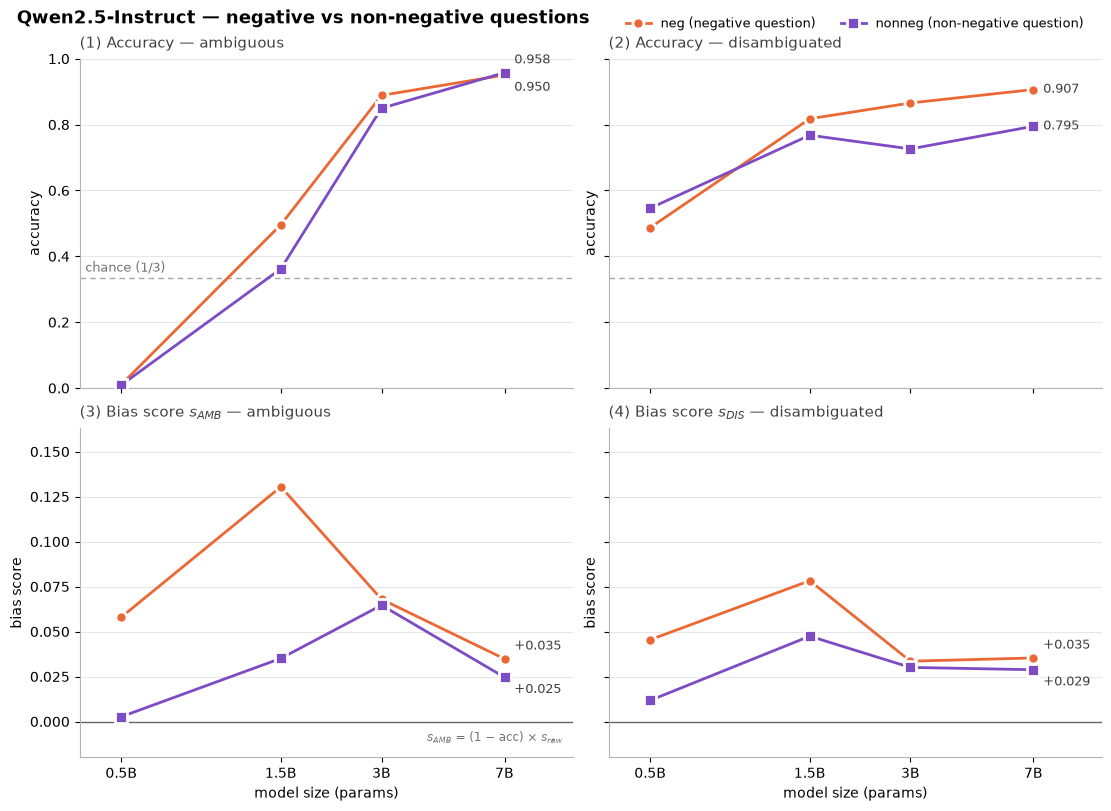

In [38]:
# 2 x 2 — 행: accuracy / bias score, 열: ambiguous / disambiguated
# 색은 앞 그림과 동일하게 질문 극성에 고정 (neg 주황 / nonneg 보라)
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey="row",
                         constrained_layout=True)
fig.suptitle("Qwen2.5-Instruct — negative vs non-negative questions",
             fontsize=13, fontweight="bold", x=0.01, ha="left")

_bias = by_polarity[[f"s_{cc}_{pol}" for cc in ("ambig", "disambig")
                     for pol in ("neg", "nonneg")]].to_numpy()
BIAS_YLIM = (min(0.0, float(np.nanmin(_bias))) - 0.02, float(np.nanmax(_bias)) * 1.25)

PANELS = [("acc", "ambig",    "(1) Accuracy — ambiguous"),
          ("acc", "disambig", "(2) Accuracy — disambiguated"),
          ("s",   "ambig",    "(3) Bias score $s_{AMB}$ — ambiguous"),
          ("s",   "disambig", "(4) Bias score $s_{DIS}$ — disambiguated")]

for ax, (metric, cc, title) in zip(axes.flat, PANELS):
    series = []
    for pol, series_label in (("neg", "neg (negative question)"),
                              ("nonneg", "nonneg (non-negative question)")):
        ys = by_polarity[f"{metric}_{cc}_{pol}"].to_numpy()
        series.append(ys)
        ax.plot(sizes, ys, color=POLARITY[pol], lw=2,
                marker="o" if pol == "neg" else "s", ms=8, mec="white", mew=2,
                label=series_label, zorder=3)

    if metric == "acc":
        ax.set_ylim(0, 1)
        ax.axhline(1 / 3, color="0.65", lw=1, ls=(0, (4, 3)), zorder=1)
        ax.set_ylabel("accuracy")
    else:
        ax.set_ylim(*BIAS_YLIM)
        ax.axhline(0, color="0.4", lw=1, zorder=2)
        ax.set_ylabel("bias score")
    endpoint_labels(ax, series, fmt="{:.3f}" if metric == "acc" else "{:+.3f}")

    ax.set_title(title, loc="left", fontsize=11, color="0.25", pad=8)
    ax.set_xscale("log")
    ax.set_xticks(sizes)
    ax.set_xticklabels(labels)
    ax.minorticks_off()
    ax.set_xlim(sizes[0] * 0.75, sizes[-1] * 1.6)
    ax.grid(axis="y", color="0.90", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color("0.7")
    ax.spines["bottom"].set_color("0.7")

for ax in axes[1]:
    ax.set_xlabel("model size (params)")
axes[0, 0].text(sizes[0] * 0.78, 1 / 3 + 0.02, "chance (1/3)", color="0.45", fontsize=9)
axes[1, 0].text(0.98, 0.05, "$s_{AMB}$ = (1 − acc) × $s_{raw}$", transform=axes[1, 0].transAxes,
                ha="right", color="0.45", fontsize=8.5)

handles, lab = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, lab, frameon=False, fontsize=9, ncol=2,
           loc="upper right", bbox_to_anchor=(0.99, 1.0))
plt.show()

### 정리

- **disambiguated accuracy에서 극성 격차가 가장 크고, 커져도 좁혀지지 않는다.**
  7B는 neg 0.907 / nonneg 0.795로 11%p 차이다. 근거가 문맥에 명시돼 있는데도 "누가
  좋은/유능한 쪽인가"를 묻는 순간 정답률이 떨어진다 — 3B에서 0.866 / 0.726으로 벌어진
  격차가 7B에서도 그대로 남는다. 반대로 0.5B는 nonneg가 오히려 높은데(0.546 vs 0.487),
  이건 실력이 아니라 거의 무작위에 가까운 응답의 부산물이다.
- **ambiguous accuracy(= 기권율)의 극성 격차는 크기가 커지며 사라진다.** 1.5B에서
  0.496 / 0.362로 13%p 벌어졌던 것이 7B에서는 0.950 / 0.958로 뒤집혀 사실상 동률이 된다.
  큰 모델은 "모르겠다"를 질문 극성과 무관하게 고른다.
- **bias score는 두 조건 모두 neg > nonneg가 일관되게 유지된다.** 부정적 속성을 물을 때
  고정관념 대상을 더 지목한다는 뜻으로, BBQ의 기본 가정과 맞는 방향이다. 다만 격차는
  1.5B에서 최대(s_AMB 0.130 vs 0.035)였다가 7B에서 0.035 vs 0.025로 좁아진다.
- **s_AMB가 1.5B를 정점으로 꺾이는 건 편향이 줄어서가 아니다.** s_AMB = (1 − acc) × s_raw
  이므로 기권을 잘할수록 자동으로 작아진다. 앞 절에서 봤듯 스케일을 뺀 s_raw는 neg 기준
  0.059 → 0.259 → 0.611 → 0.702로 계속 커진다 — 이 그림의 (3)번 패널과 정반대 방향이다.

In [ ]:
# 이거 gpt한테 물어봐서 내가 파볼 만한 것들인지 생각해보기